# Giza to the Citadel: gpx-to-geojson on real Cairo coordinates

Question: how long is a route from the Great Pyramid of Giza to the Citadel of Saladin via Cairo Tower and Tahrir Square, and how is that length split over its legs?

Run this notebook from the `showcase/` folder (or the repository root).

In [1]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / 'showcase').is_dir() else Path.cwd().parent
sys.path.insert(0, str(root / 'src'))
sys.path.insert(0, str(root / 'showcase'))
import make_showcase as ms

gpx = root / 'showcase' / 'data' / 'cairo.gpx'
print(gpx.read_text(encoding='utf-8')[:400])

<?xml version="1.0" encoding="UTF-8"?>
<gpx version="1.1" creator="gpx-to-geojson examples" xmlns="http://www.topografix.com/GPX/1/1">
  <wpt lat="29.9792" lon="31.1342"><name>Great Pyramid of Giza</name></wpt>
  <wpt lat="30.0459" lon="31.2243"><name>Cairo Tower</name></wpt>
  <wpt lat="30.0478" lon="31.2336"><name>Tahrir Square</name></wpt>
  <wpt lat="30.0287" lon="31.2599"><name>Citadel of Sal


## Run the tool

`convert` reads the GPX and returns a GeoJSON FeatureCollection (lon/lat, WGS84). Route length is geodesic, in metres.

In [2]:
from gpx_to_geojson import convert

fc = convert(gpx)
route = [f for f in fc['features'] if f['properties']['kind'] == 'route'][0]
print(route['properties']['name'], route['properties']['distance_m'], 'm')

Giza to Citadel 15637.09 m


## Inspect the result

`build_collection` adds one feature per route leg, with its geodesic length from `pyproj.Geod` (WGS84).

In [3]:
collection = ms.build_collection(gpx)
rows = [(f['properties']['kind'], f['properties'].get('name') or f"{f['properties']['from']} -> {f['properties']['to']}",
         f['properties'].get('distance_m')) for f in collection['features']]
print(f"{'kind':<10}{'name / leg':<48}{'distance_m':>12}")
for kind, name, d in rows:
    print(f"{kind:<10}{name:<48}{'' if d is None else format(d, '.2f'):>12}")

kind      name / leg                                        distance_m
waypoint  Great Pyramid of Giza                                       
waypoint  Cairo Tower                                                 
waypoint  Tahrir Square                                               
waypoint  Citadel of Saladin                                          
route     Giza to Citadel                                     15637.09
leg       Great Pyramid of Giza -> Cairo Tower                11411.65
leg       Cairo Tower -> Tahrir Square                          921.30
leg       Tahrir Square -> Citadel of Saladin                  3304.14


## Map

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-kd9h41vr because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


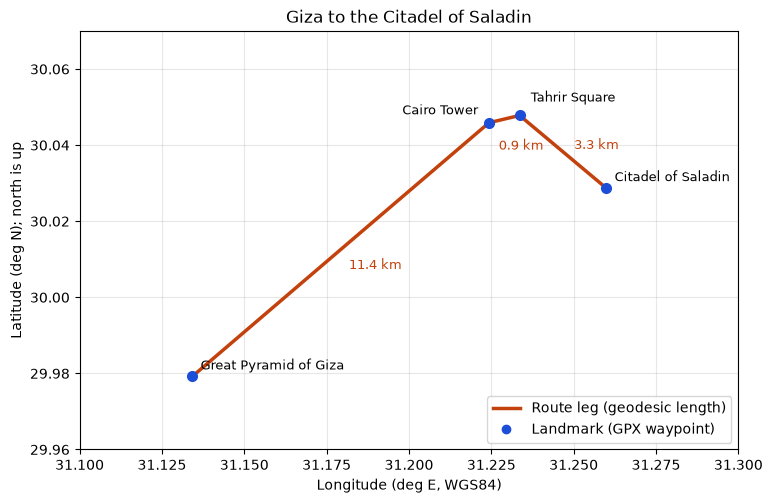

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 7))
ms.plot(collection, ax)
ax.set_title('Giza to the Citadel of Saladin')
plt.show()